# 員工離職分析：驅動因素、風險預測與留任行動

**問題**：公司過去一段期間離職率 16.1%。哪些因素和離職最相關？哪些在職員工風險最高？把資源投在哪裡最划算？

**資料**：IBM HR Analytics Employee Attrition & Performance（Kaggle），1,470 名員工、35 個欄位。
此為 IBM 資料科學家**虛構**的資料集，結論只代表這份資料，不代表任何真實公司。

**分析流程**
1. 資料檢查與整理
2. 探索式分析（EDA）：整體、人口統計、工作條件、薪酬、年資、滿意度問卷
3. 統計檢定：哪些差異不是偶然
4. 預測模型：邏輯迴歸為主，樹模型對照
5. 風險分群與商業試算：高風險名單、離職成本、加班改善情境
6. 匯出 Tableau 資料表

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import font_manager
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
OUT_TAB = ROOT / "outputs" / "tableau"
OUT_FIG = ROOT / "outputs" / "figures"
OUT_TAB.mkdir(parents=True, exist_ok=True)
OUT_FIG.mkdir(parents=True, exist_ok=True)
SEED = 42

# 中文字型：依序找系統上有的字型
for f in ["Noto Sans CJK TC", "Microsoft JhengHei", "PingFang TC", "Heiti TC", "Noto Sans TC", "Arial Unicode MS"]:
    if any(f == x.name for x in font_manager.fontManager.ttflist):
        plt.rcParams["font.family"] = f
        break
else:
    print("找不到中文字型，圖表中文會變成方框。Linux 可安裝 fonts-noto-cjk 後重開 kernel。")
plt.rcParams.update({"axes.unicode_minus": False, "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold"})

# 與 Tableau 儀表板一致的藍灰配色：深藍＝離職，藍灰＝留任
C_LEFT, C_STAY, C_LIGHT = "#2563A8", "#8C99A6", "#D6DEE6"

def savefig(name):
    plt.savefig(OUT_FIG / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()

## 1. 資料檢查與整理

In [2]:
raw = pd.read_csv(DATA)
print(raw.shape)
print("缺值總數：", raw.isna().sum().sum(), "｜重複列：", raw.duplicated().sum(),
      "｜員工編號重複：", raw.EmployeeNumber.duplicated().sum())
raw.head()

(1470, 35)
缺值總數： 0 ｜重複列： 0 ｜員工編號重複： 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


In [3]:
# 只有單一值的欄位沒有資訊
const_cols = [c for c in raw.columns if raw[c].nunique() == 1]
print("單一值欄位：", const_cols)

# DailyRate / HourlyRate / MonthlyRate 名稱像薪資，但和 MonthlyIncome 幾乎無關，判斷為隨機產生的欄位
raw[["MonthlyIncome", "DailyRate", "HourlyRate", "MonthlyRate", "JobLevel"]].corr(method="spearman").round(2)

單一值欄位： ['EmployeeCount', 'Over18', 'StandardHours']


,MonthlyIncome,DailyRate,HourlyRate,MonthlyRate,JobLevel
MonthlyIncome,1.000,0.020,-0.020,0.050,0.920
DailyRate,0.020,1.000,0.020,-0.030,0.000
HourlyRate,-0.020,0.020,1.000,-0.010,-0.030
MonthlyRate,0.050,-0.030,-0.010,1.000,0.050
JobLevel,0.920,0.000,-0.030,0.050,1.000


**觀察**
- 沒有缺值、沒有重複，不需要清洗，主要工作是把代碼轉成可讀標籤、建立分組。
- `EmployeeCount`、`StandardHours`、`Over18` 只有單一值，刪除。
- `MonthlyIncome` 和職級的相關係數約 0.9，是可信的薪資欄位；`DailyRate`、`HourlyRate`、`MonthlyRate` 和薪資、職級幾乎無關，
  分析薪酬時**只用 MonthlyIncome**。這三欄仍留在模型中，交給模型判斷（預期沒有作用）。

In [4]:
df = raw.drop(columns=const_cols).copy()
df["AttritionFlag"] = (df["Attrition"] == "Yes").astype(int)

# 代碼 → 標籤（依 IBM 官方資料字典）
LABELS = {
    "Education": {1: "高中以下", 2: "專科", 3: "學士", 4: "碩士", 5: "博士"},
    "EnvironmentSatisfaction": {1: "低", 2: "中", 3: "高", 4: "非常高"},
    "JobSatisfaction": {1: "低", 2: "中", 3: "高", 4: "非常高"},
    "RelationshipSatisfaction": {1: "低", 2: "中", 3: "高", 4: "非常高"},
    "JobInvolvement": {1: "低", 2: "中", 3: "高", 4: "非常高"},
    "WorkLifeBalance": {1: "差", 2: "普通", 3: "良好", 4: "很好"},
    "PerformanceRating": {3: "優良", 4: "傑出"},
    "StockOptionLevel": {0: "無", 1: "等級 1", 2: "等級 2", 3: "等級 3"},
}
ZH = {
    "Department": {"Research & Development": "研發", "Sales": "業務", "Human Resources": "人資"},
    "BusinessTravel": {"Non-Travel": "不出差", "Travel_Rarely": "偶爾出差", "Travel_Frequently": "經常出差"},
    "MaritalStatus": {"Single": "單身", "Married": "已婚", "Divorced": "離婚"},
    "Gender": {"Male": "男", "Female": "女"},
    "OverTime": {"Yes": "有加班", "No": "無加班"},
}
for c, m in {**LABELS, **ZH}.items():
    df[f"{c}_Label"] = df[c].map(m)

def band(s, bins, labels):
    return pd.cut(s, bins=bins, labels=labels, right=False).astype(str)

df["AgeGroup"] = band(df.Age, [0, 25, 35, 45, 55, 100], ["<25", "25-34", "35-44", "45-54", "55+"])
df["TenureBand"] = band(df.YearsAtCompany, [0, 1, 3, 6, 11, 100], ["未滿 1 年", "1-2 年", "3-5 年", "6-10 年", "10 年以上"])
df["IncomeBand"] = band(df.MonthlyIncome, [0, 2500, 5000, 7500, 10000, 1e9], ["<2.5k", "2.5k-5k", "5k-7.5k", "7.5k-10k", "10k+"])
df["DistanceBand"] = band(df.DistanceFromHome, [0, 6, 11, 21, 100], ["≤5", "6-10", "11-20", "21+"])
df["PromotionGapBand"] = band(df.YearsSinceLastPromotion, [0, 1, 3, 6, 100], ["今年", "1-2 年", "3-5 年", "6 年以上"])
df["CompaniesBand"] = band(df.NumCompaniesWorked, [0, 2, 5, 100], ["0-1 家", "2-4 家", "5 家以上"])

ORDER = {
    "AgeGroup": ["<25", "25-34", "35-44", "45-54", "55+"],
    "TenureBand": ["未滿 1 年", "1-2 年", "3-5 年", "6-10 年", "10 年以上"],
    "IncomeBand": ["<2.5k", "2.5k-5k", "5k-7.5k", "7.5k-10k", "10k+"],
    "DistanceBand": ["≤5", "6-10", "11-20", "21+"],
    "PromotionGapBand": ["今年", "1-2 年", "3-5 年", "6 年以上"],
    "CompaniesBand": ["0-1 家", "2-4 家", "5 家以上"],
    "BusinessTravel_Label": ["不出差", "偶爾出差", "經常出差"],
}
for c in ["EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction", "JobInvolvement",
          "WorkLifeBalance", "Education", "StockOptionLevel"]:
    ORDER[f"{c}_Label"] = list(LABELS[c].values())
df.shape

(1470, 52)

## 2. 探索式分析

### 2.1 整體概況

In [5]:
n, left = len(df), df.AttritionFlag.sum()
P0 = left / n
print(f"員工 {n:,} 人｜離職 {left} 人｜在職 {n-left:,} 人｜離職率 {P0:.1%}")

def wilson(k, n, z=1.96):
    # 比例的 Wilson 95% 信賴區間，小樣本比常態近似可靠
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

def rate_table(col, data=df):
    g = data.groupby(col, observed=True).AttritionFlag.agg(Employees="size", Leavers="sum").reset_index()
    g["AttritionRate"] = g.Leavers / g.Employees
    g[["CI_low", "CI_high"]] = [wilson(k, m) for k, m in zip(g.Leavers, g.Employees)]
    g["Lift"] = g.AttritionRate / P0
    if col in ORDER:
        g[col] = pd.Categorical(g[col], ORDER[col], ordered=True)
        g = g.sort_values(col)
    return g

def plot_rates(cols, titles, ncols=3, sort=False, fname=None):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows), squeeze=False)
    for ax, col, t in zip(axes.flat, cols, titles):
        g = rate_table(col)
        if sort:
            g = g.sort_values("AttritionRate")
        y = np.arange(len(g))
        color = [C_LEFT if r > P0 else C_STAY for r in g.AttritionRate]
        ax.barh(y, g.AttritionRate, color=color, height=0.6)
        ax.errorbar(g.AttritionRate, y, xerr=[g.AttritionRate - g.CI_low, g.CI_high - g.AttritionRate],
                    fmt="none", ecolor="#888", capsize=3, lw=1)
        ax.axvline(P0, ls="--", c="#999", lw=1)
        ax.set_yticks(y, [f"{a}（n={b}）" for a, b in zip(g[col], g.Employees)])
        ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
        ax.set_title(t)
    for ax in axes.flat[len(cols):]:
        ax.axis("off")
    fig.tight_layout()
    if fname:
        savefig(fname)

員工 1,470 人｜離職 237 人｜在職 1,233 人｜離職率 16.1%


圖例：深藍長條高於全公司平均（虛線），藍灰低於平均；誤差線為 Wilson 95% 信賴區間（Wilson, 1927）。

### 2.2 組織與人口統計

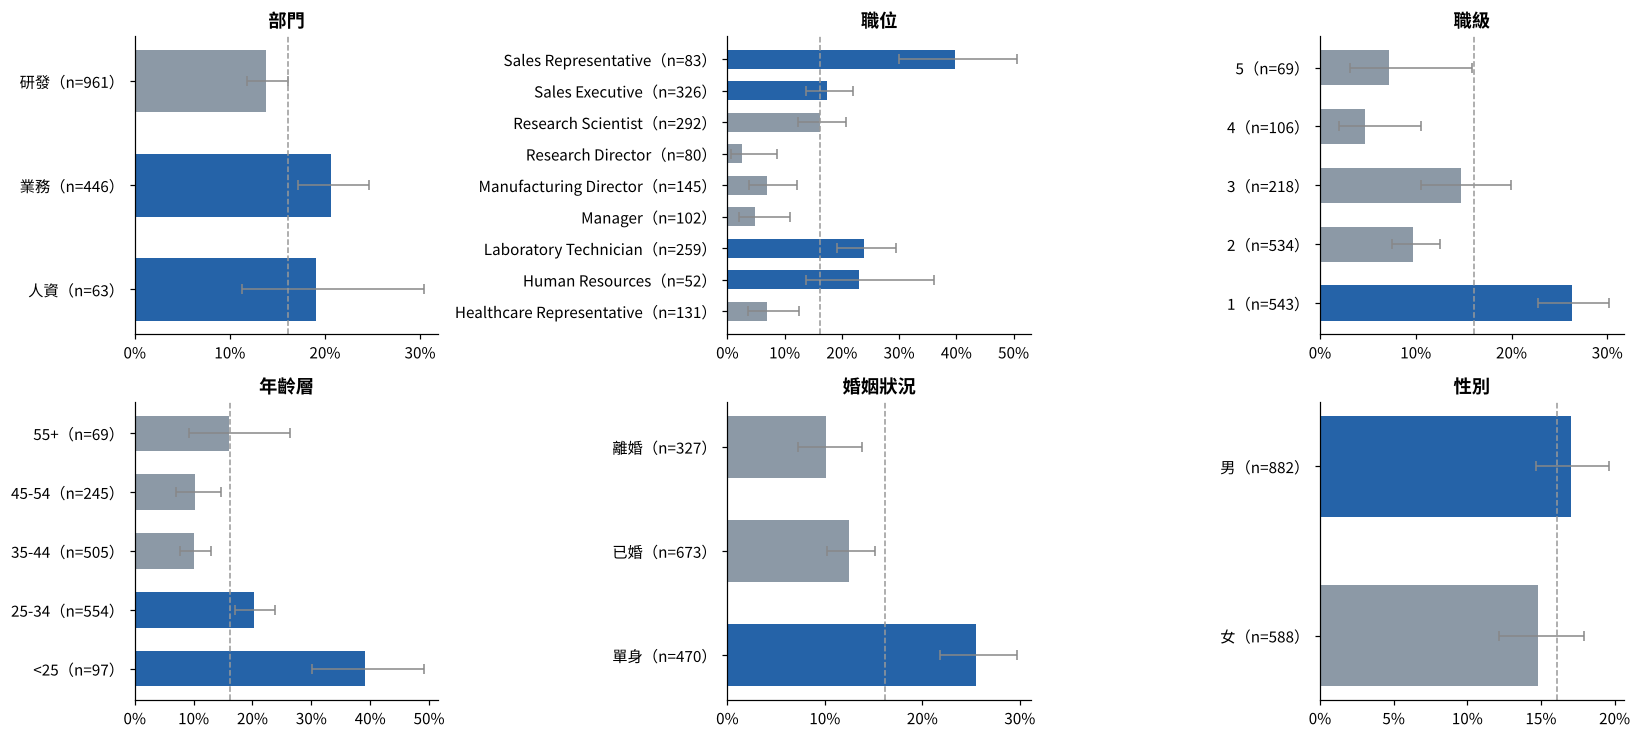

In [6]:
plot_rates(["Department_Label", "JobRole", "JobLevel", "AgeGroup", "MaritalStatus_Label", "Gender_Label"],
           ["部門", "職位", "職級", "年齡層", "婚姻狀況", "性別"], sort=False, fname="01_org_demographics")

**觀察**
- **職位差異最大**：Sales Representative 約 40%，Research Director、Manager 不到 5%。部門層級（業務 20.6%、研發 13.8%）會掩蓋這個差異。
- **職級 1 離職率 26%**，是其他職級的 2–5 倍；年輕（<25 歲約 39%）、單身（26%）族群也明顯偏高。
- 年齡、職級、年資、薪資彼此高度相關（下一節會處理），單看任一個都會高估它的獨立影響。
- 性別差距小（女 14.8%、男 17.0%），信賴區間重疊。

### 2.3 工作條件

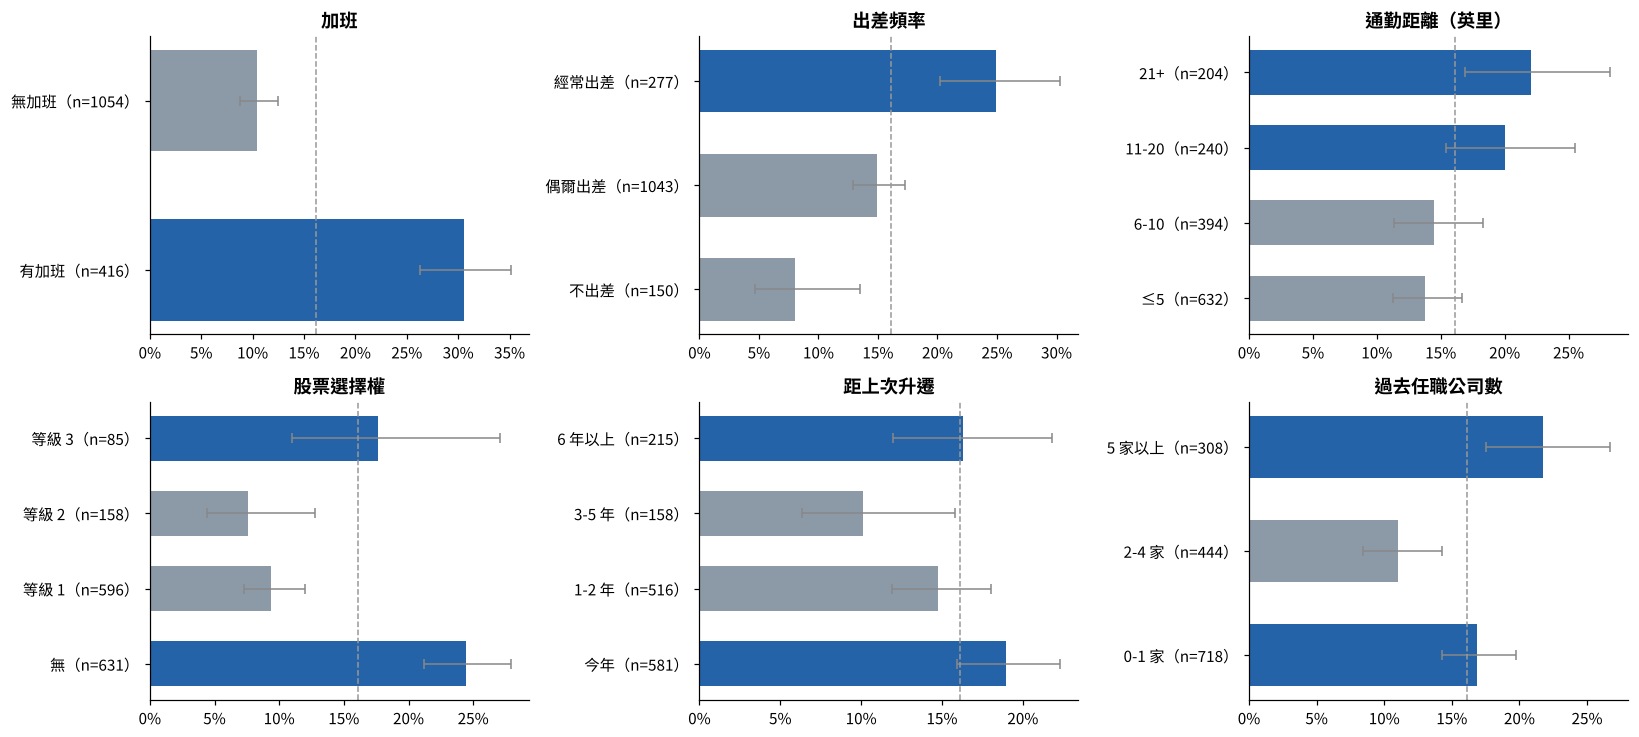

In [7]:
plot_rates(["OverTime_Label", "BusinessTravel_Label", "DistanceBand", "StockOptionLevel_Label", "PromotionGapBand", "CompaniesBand"],
           ["加班", "出差頻率", "通勤距離（英里）", "股票選擇權", "距上次升遷", "過去任職公司數"], fname="02_work_conditions")

**觀察**
- **加班是最強的單一訊號**：有加班 30.5%、無加班 10.4%，約 3 倍，而且加班是公司**可以直接管理**的變數。
- 經常出差 24.9%，是不出差的 3 倍。
- 沒有股票選擇權 24.4%；但等級 3 又回升到 17.6%（樣本只有 85 人，信賴區間很寬）。
- 「距上次升遷」沒有單調關係，不是好的指標。

### 2.4 薪酬與年資

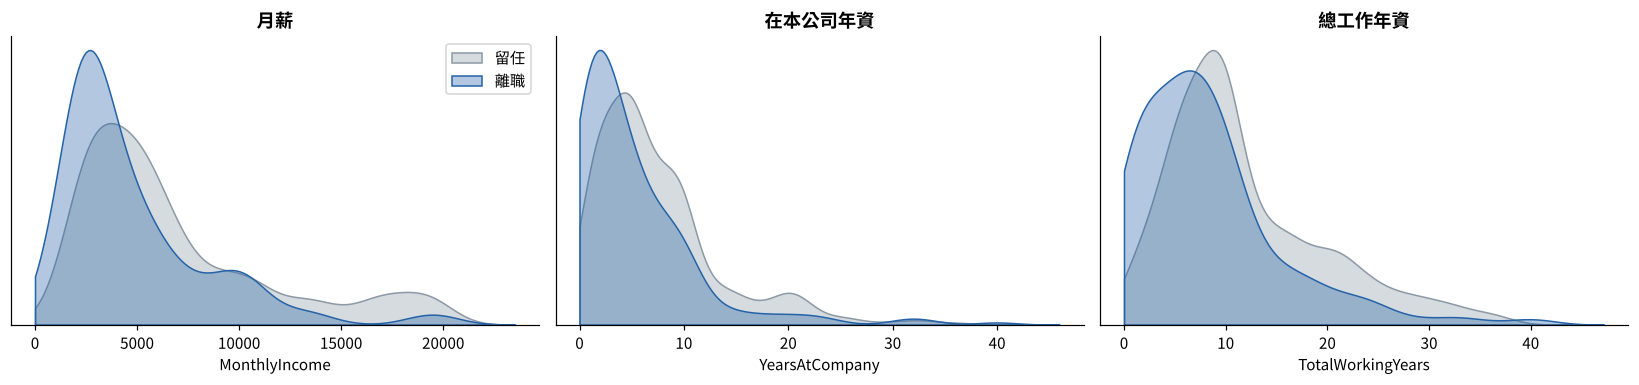

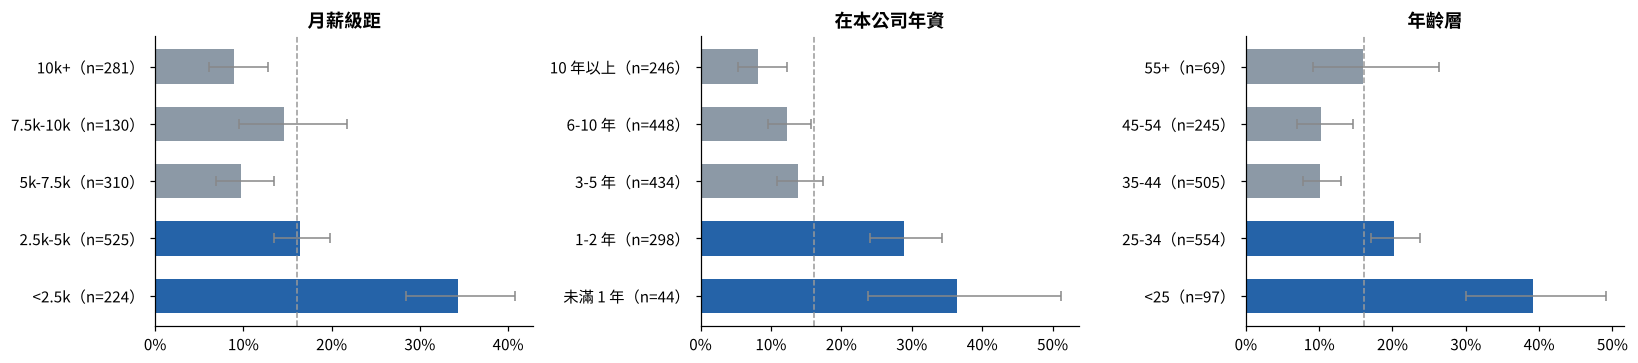

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, t in zip(axes, ["MonthlyIncome", "YearsAtCompany", "TotalWorkingYears"],
                      ["月薪", "在本公司年資", "總工作年資"]):
    for flag, c, lab in [(0, C_STAY, "留任"), (1, C_LEFT, "離職")]:
        sns.kdeplot(df.loc[df.AttritionFlag == flag, col], ax=ax, fill=True, color=c, alpha=.35,
                    label=lab, common_norm=False, clip=(0, None))
    ax.set_title(t); ax.set_ylabel(""); ax.set_yticks([])
axes[0].legend()
fig.tight_layout(); savefig("03_income_tenure_dist")

plot_rates(["IncomeBand", "TenureBand", "AgeGroup"], ["月薪級距", "在本公司年資", "年齡層"], fname="04_income_tenure_rates")

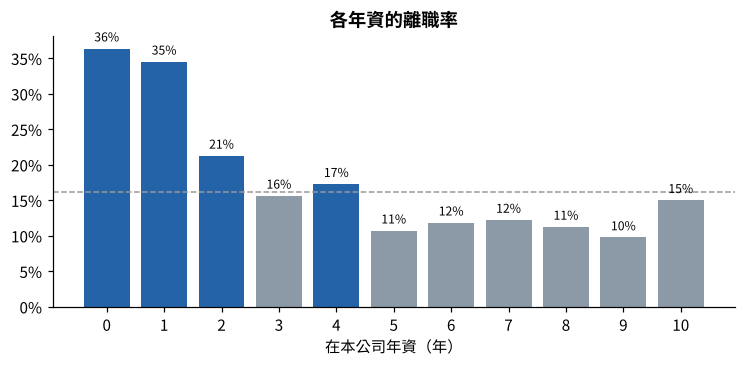

In [9]:
# 第一年流失：年資 0-10 年逐年離職率
yr = rate_table("YearsAtCompany").query("YearsAtCompany <= 10")
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(yr.YearsAtCompany, yr.AttritionRate, color=[C_LEFT if r > P0 else C_STAY for r in yr.AttritionRate])
ax.axhline(P0, ls="--", c="#999", lw=1)
for x, r, m in zip(yr.YearsAtCompany, yr.AttritionRate, yr.Employees):
    ax.text(x, r + .01, f"{r:.0%}", ha="center", fontsize=8)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xticks(yr.YearsAtCompany); ax.set_xlabel("在本公司年資（年）"); ax.set_title("各年資的離職率")
savefig("05_tenure_curve")

**觀察**
- 離職者集中在**低薪、資淺**：月薪 2,500 以下約 34%，年資 0–1 年約 35%（0 年的 44 人中 36%、1 年的 171 人中 35%）。
- 年資 2 年約 21%，3 年起大多降到約 10–15%，代表**前兩年是留任關鍵期**，適合把資源放在到職、導師制度、第一次調薪節點。

### 2.5 薪酬公平性檢查（同職級比較）

In [10]:
pay = df.pivot_table(index="JobLevel", columns="Gender_Label", values="MonthlyIncome", aggfunc="median")
pay["女/男"] = pay["女"] / pay["男"]
for lv, g in df.groupby("JobLevel"):
    pay.loc[lv, "p 值（Mann-Whitney）"] = stats.mannwhitneyu(g.loc[g.Gender == "Female", "MonthlyIncome"],
                                                        g.loc[g.Gender == "Male", "MonthlyIncome"]).pvalue
pay.round(3)

Gender_Label,女,男,女/男,p 值（Mann-Whitney）
JobLevel,,,,
1,"2,659.000","2,678.500",0.993,0.974
2,"5,247.500","5,383.500",0.975,0.477
3,"10,052.000","9,854.000",1.020,0.474
4,"16,064.000","16,328.000",0.984,0.312
5,"19,071.500","19,246.000",0.991,0.431


同一職級內，男女月薪中位數差距都在 ±3% 內，檢定都不顯著：這份資料**沒有**看到性別薪資落差。

### 2.6 滿意度問卷

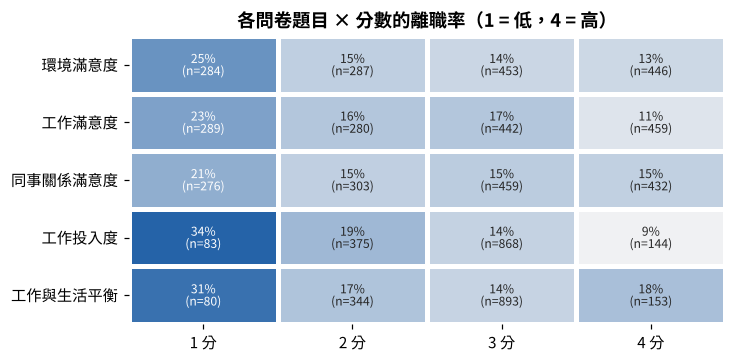

In [11]:
SURVEY = {"EnvironmentSatisfaction": "環境滿意度", "JobSatisfaction": "工作滿意度",
          "RelationshipSatisfaction": "同事關係滿意度", "JobInvolvement": "工作投入度", "WorkLifeBalance": "工作與生活平衡"}
heat = pd.DataFrame({v: df.groupby(k).AttritionFlag.mean() for k, v in SURVEY.items()}).T
heat.columns = [f"{c} 分" for c in heat.columns]
cnt = pd.DataFrame({v: df.groupby(k).size() for k, v in SURVEY.items()}).T
fig, ax = plt.subplots(figsize=(7, 3.4))
sns.heatmap(heat, annot=heat.map(lambda x: f"{x:.0%}") + "\n(n=" + cnt.astype(str).values + ")", fmt="",
            cmap=sns.light_palette(C_LEFT, as_cmap=True), cbar=False, ax=ax, linewidths=2, annot_kws={"fontsize": 8})
ax.set_title("各問卷題目 × 分數的離職率（1 = 低，4 = 高）")
savefig("06_survey_heatmap")

**觀察**：五題中，工作投入度 1 分（34%）、工作與生活平衡 1 分（31%）、環境滿意度 1 分（25%）風險最高。
「同事關係滿意度」幾乎沒有區分力。問卷最低分族群人數不多，但可以作為主管面談的觸發條件。

### 2.7 交叉分析：風險會疊加

In [12]:
df["IsJobLevel1"] = np.where(df.JobLevel == 1, "職級 1", "職級 2+")
x = df.pivot_table(index="OverTime_Label", columns="IsJobLevel1", values="AttritionFlag", aggfunc=["mean", "size"])
display(x.round(3))

combo = (df.assign(Seg=lambda d: d.OverTime_Label + "｜" + d.IsJobLevel1 + "｜" + d.MaritalStatus_Label)
           .pipe(lambda d: rate_table("Seg", d)).query("Employees >= 30").sort_values("AttritionRate", ascending=False))
combo.head(8)

mean       size      
IsJobLevel1     職級 1 職級 2+ 職級 1 職級 2+
OverTime_Label                       
有加班            0.526 0.173  156   260
無加班            0.158 0.073  387   667

,Seg,Employees,Leavers,AttritionRate,CI_low,CI_high,Lift
0,有加班｜職級 1｜單身,59,40,0.678,0.551,0.783,4.205
2,有加班｜職級 1｜離婚,34,15,0.441,0.289,0.605,2.736
1,有加班｜職級 1｜已婚,63,27,0.429,0.314,0.551,2.658
3,有加班｜職級 2+｜單身,72,25,0.347,0.248,0.462,2.154
6,無加班｜職級 1｜單身,143,38,0.266,0.200,0.344,1.648
4,有加班｜職級 2+｜已婚,123,16,0.130,0.082,0.201,0.807
8,無加班｜職級 1｜離婚,75,8,0.107,0.055,0.197,0.662
7,無加班｜職級 1｜已婚,169,15,0.089,0.055,0.141,0.551


**觀察**：加班 × 職級 1 的離職率約 **53%**（156 人），是「無加班、職級 2+」（7%）的 7 倍；再加上單身達 **68%**（59 人）。
這群人規模小、風險極高，是最適合優先介入的對象。

## 3. 統計檢定

類別變數用卡方檢定，效果量用 Cramér's V（Cramér, 1946）；數值變數用 Mann-Whitney U 檢定（Mann & Whitney, 1947），效果量用 rank-biserial 相關（Kerby, 2014）。共做約 30 次檢定，以 Benjamini-Hochberg 程序控制偽發現率（Benjamini & Hochberg, 1995）。

In [13]:
CAT = ["OverTime", "JobLevel", "StockOptionLevel", "MaritalStatus", "JobRole", "BusinessTravel", "Department",
       "EducationField", "Gender", "Education", "PerformanceRating", "EnvironmentSatisfaction", "JobSatisfaction",
       "JobInvolvement", "WorkLifeBalance", "RelationshipSatisfaction"]
NUM = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole", "YearsWithCurrManager",
       "YearsSinceLastPromotion", "NumCompaniesWorked", "DistanceFromHome", "PercentSalaryHike",
       "TrainingTimesLastYear", "DailyRate", "HourlyRate", "MonthlyRate"]
rows = []
for c in CAT:
    tab = pd.crosstab(df[c], df.AttritionFlag)
    chi2, p, dof, _ = stats.chi2_contingency(tab)
    rows.append(dict(Feature=c, Type="類別", Test="卡方", p=p, Effect=np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1)))))
for c in NUM:
    a, b = df.loc[df.AttritionFlag == 1, c], df.loc[df.AttritionFlag == 0, c]
    u, p = stats.mannwhitneyu(a, b)
    rows.append(dict(Feature=c, Type="數值", Test="Mann-Whitney", p=p, Effect=2 * u / (len(a) * len(b)) - 1,
                     Median_Left=a.median(), Median_Stay=b.median()))
tests = pd.DataFrame(rows)
# Benjamini-Hochberg
m = len(tests); order = tests.p.rank(method="first")
tests["p_adj"] = (tests.p * m / order).sort_values(ascending=False).cummin().reindex(tests.index).clip(upper=1)
tests["顯著（FDR 5%）"] = tests.p_adj < .05
tests["|Effect|"] = tests.Effect.abs()
tests = tests.sort_values("|Effect|", ascending=False).drop(columns="|Effect|")
tests.round(4)

,Feature,Type,Test,p,Effect,Median_Left,Median_Stay,p_adj,顯著（FDR 5%）
18,TotalWorkingYears,數值,Mann-Whitney,0.000,-0.312,7.000,10.000,0.000,True
17,MonthlyIncome,數值,Mann-Whitney,0.000,-0.311,"3,202.000","5,204.000",0.000,True
19,YearsAtCompany,數值,Mann-Whitney,0.000,-0.298,3.000,6.000,0.000,True
20,YearsInCurrentRole,數值,Mann-Whitney,0.000,-0.280,2.000,3.000,0.000,True
21,YearsWithCurrManager,數值,Mann-Whitney,0.000,-0.272,2.000,3.000,0.000,True
16,Age,數值,Mann-Whitney,0.000,-0.269,32.000,36.000,0.000,True
0,OverTime,類別,卡方,0.000,0.244,NaN,NaN,0.000,True
4,JobRole,類別,卡方,0.000,0.242,NaN,NaN,0.000,True
1,JobLevel,類別,卡方,0.000,0.222,NaN,NaN,0.000,True
2,StockOptionLevel,類別,卡方,0.000,0.203,NaN,NaN,0.000,True


**解讀**：依 Cohen（1988）的慣例，效果量約 0.1 為小、0.3 為中。
- **數值變數**：總工作年資、月薪、在本公司年資、年齡等資歷類變數效果最大（|r| 約 0.27–0.31，Effect 為負代表離職者數值較低）；通勤距離為正（離職者通勤較遠），但效果小。
- **類別變數**：加班（V=0.24）、職位（0.24）、職級（0.22）、股票選擇權（0.20）、婚姻（0.18）最強。
- **不顯著**：績效評等、同事關係、學歷、性別、加薪幅度、過去任職公司數、距上次升遷、HourlyRate、MonthlyRate。
- DailyRate 校正後勉強顯著（p_adj≈0.04），效果極小，判斷為雜訊，不納入解讀。

### 3.1 共線性：年齡、職級、薪資、年資其實是同一件事

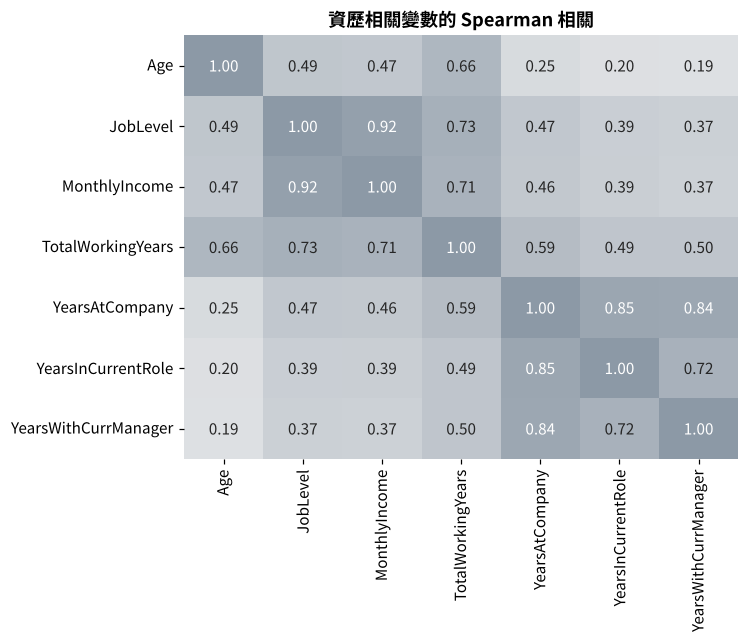

In [14]:
seniority = ["Age", "JobLevel", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany", "YearsInCurrentRole", "YearsWithCurrManager"]
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(df[seniority].corr(method="spearman"), annot=True, fmt=".2f", cmap=sns.light_palette(C_STAY, as_cmap=True), vmin=0, vmax=1, ax=ax, cbar=False)
ax.set_title("資歷相關變數的 Spearman 相關"); savefig("07_seniority_corr")

這些變數相關係數多在 0.5–0.95，代表「資淺」是同一個潛在因素。建模時用正則化的邏輯迴歸處理，並且不把單一係數解讀成獨立因果效果。

## 4. 預測模型

**目標**：對每位員工估計離職機率，讓 HR 在有限資源下優先關懷高風險者。

**設計**
- 分層切分 80% 訓練、20% 測試；模型選擇只在訓練集用 5 折交叉驗證，測試集最後只看一次。
- 主要指標用 **PR-AUC**；在類別不平衡的資料中，PR 曲線比 ROC 曲線更能反映模型辨識少數類別的能力（Saito & Rehmsmeier, 2015）。隨機猜測的基準約 0.16，ROC-AUC 為輔。
- 候選模型：邏輯迴歸（可解釋）、隨機森林、梯度提升樹。

In [15]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, precision_recall_curve, roc_curve
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

ID = "EmployeeNumber"
CAT_X = ["BusinessTravel", "Department", "EducationField", "Gender", "JobRole", "MaritalStatus", "OverTime"]
NUM_X = [c for c in raw.columns if c not in CAT_X + const_cols + ["Attrition", ID]]
X, y = df[CAT_X + NUM_X], df.AttritionFlag
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
print(f"訓練 {len(X_tr)}（離職 {y_tr.sum()}）｜測試 {len(X_te)}（離職 {y_te.sum()}）｜特徵 {len(CAT_X)} 類別 + {len(NUM_X)} 數值")

pre = ColumnTransformer([("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT_X),
                         ("num", StandardScaler(), NUM_X)])
models = {
    "邏輯迴歸": Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=5000))]),
    "隨機森林": Pipeline([("pre", pre), ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1))]),
    "梯度提升樹": Pipeline([("pre", pre), ("clf", HistGradientBoostingClassifier(learning_rate=.05, max_depth=3, random_state=SEED))]),
}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
res = {k: cross_validate(m, X_tr, y_tr, cv=cv, scoring=["roc_auc", "average_precision"]) for k, m in models.items()}
pd.DataFrame({k: {"ROC-AUC": f"{v['test_roc_auc'].mean():.3f} ± {v['test_roc_auc'].std():.3f}",
                  "PR-AUC": f"{v['test_average_precision'].mean():.3f} ± {v['test_average_precision'].std():.3f}"}
              for k, v in res.items()}).T

訓練 1176（離職 190）｜測試 294（離職 47）｜特徵 7 類別 + 23 數值


,ROC-AUC,PR-AUC
邏輯迴歸,0.838 ± 0.030,0.652 ± 0.062
隨機森林,0.812 ± 0.033,0.560 ± 0.082
梯度提升樹,0.803 ± 0.022,0.579 ± 0.043


邏輯迴歸在兩個指標都最好。資料量小（1,176 筆訓練）、訊號大致是線性且可加的，複雜模型反而容易過度擬合。接著調整正則化強度 C。

In [16]:
grid = GridSearchCV(models["邏輯迴歸"], {"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3]}, cv=cv, scoring="average_precision")
grid.fit(X_tr, y_tr)
print("最佳 C：", grid.best_params_["clf__C"], f"｜CV PR-AUC {grid.best_score_:.3f}")
pd.DataFrame(grid.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]].round(3)

最佳 C： 1 ｜CV PR-AUC 0.652


,param_clf__C,mean_test_score,std_test_score
0,0.010,0.594,0.090
1,0.030,0.621,0.072
2,0.100,0.643,0.059
3,0.300,0.649,0.062
4,1.000,0.652,0.062
5,3.000,0.650,0.060


{'ROC-AUC': 0.81, 'PR-AUC': 0.593, 'PR-AUC 隨機基準': np.float64(0.16), 'Brier': 0.098}


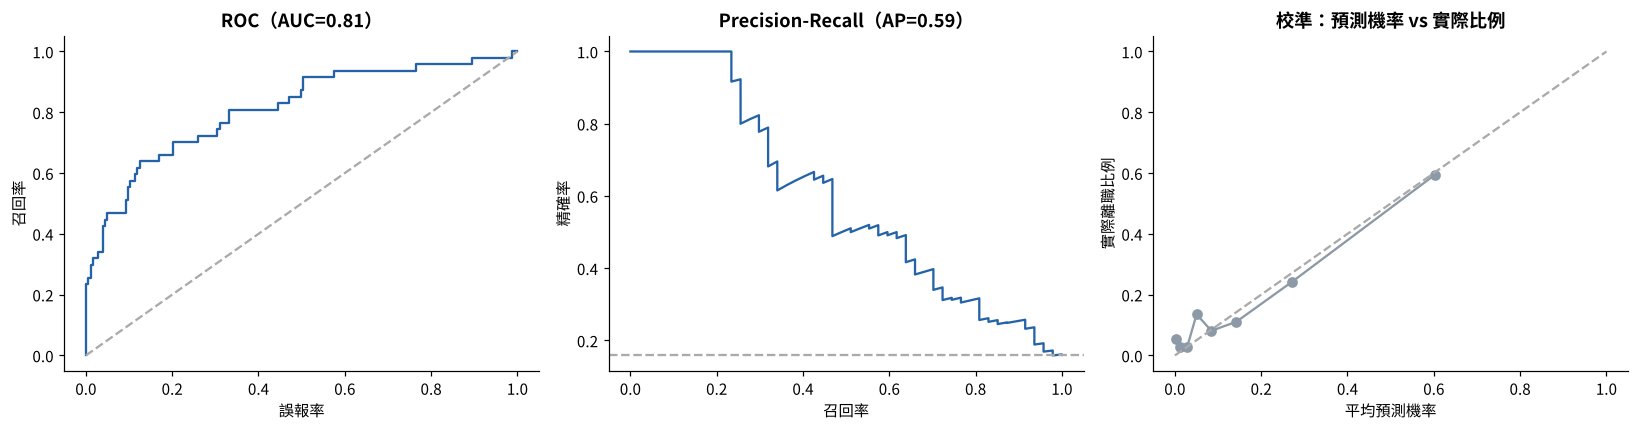

In [17]:
best = grid.best_estimator_
p_te = best.predict_proba(X_te)[:, 1]
test_metrics = {"ROC-AUC": roc_auc_score(y_te, p_te), "PR-AUC": average_precision_score(y_te, p_te),
                "PR-AUC 隨機基準": y_te.mean(), "Brier": brier_score_loss(y_te, p_te)}
print({k: round(v, 3) for k, v in test_metrics.items()})

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fpr, tpr, _ = roc_curve(y_te, p_te)
axes[0].plot(fpr, tpr, c=C_LEFT); axes[0].plot([0, 1], [0, 1], "--", c="#aaa")
axes[0].set(title=f"ROC（AUC={test_metrics['ROC-AUC']:.2f}）", xlabel="誤報率", ylabel="召回率")
pr, rc, _ = precision_recall_curve(y_te, p_te)
axes[1].plot(rc, pr, c=C_LEFT); axes[1].axhline(y_te.mean(), ls="--", c="#aaa")
axes[1].set(title=f"Precision-Recall（AP={test_metrics['PR-AUC']:.2f}）", xlabel="召回率", ylabel="精確率")
fx, fy = calibration_curve(y_te, p_te, n_bins=8, strategy="quantile")
axes[2].plot(fy, fx, "o-", c=C_STAY); axes[2].plot([0, 1], [0, 1], "--", c="#aaa")
axes[2].set(title="校準：預測機率 vs 實際比例", xlabel="平均預測機率", ylabel="實際離職比例")
fig.tight_layout(); savefig("08_model_eval")

### 4.1 業務問題應用：只能關懷前 X% 的人時，抓得到多少離職者？

In [18]:
def gains(y_true, score, pcts=(.05, .10, .15, .20, .30, .40, .50)):
    o = np.argsort(-score); yt = np.asarray(y_true)[o]
    rows = []
    for q in pcts:
        k = int(round(q * len(yt)))
        rows.append({"關懷名單比例": f"{q:.0%}", "名單人數": k, "命中離職者": int(yt[:k].sum()),
                     "名單精確率": yt[:k].mean(), "抓到離職者比例": yt[:k].sum() / yt.sum(), "Lift": yt[:k].mean() / yt.mean()})
    return pd.DataFrame(rows)
gains(y_te, p_te)

,關懷名單比例,名單人數,命中離職者,名單精確率,抓到離職者比例,Lift
0,5%,15,12,0.800,0.255,5.004
1,10%,29,19,0.655,0.404,4.098
2,15%,44,22,0.500,0.468,3.128
3,20%,59,29,0.492,0.617,3.075
4,30%,88,33,0.375,0.702,2.346
5,40%,118,36,0.305,0.766,1.908
6,50%,147,38,0.259,0.809,1.617


**解讀**：在測試集上，只關懷風險最高的 20% 員工（59 人），就能涵蓋約 62% 的離職者；名單中約一半真的離職，約為隨機挑人的 3 倍。
這是比「準確率」更有用的說法：它直接回答「HR 時間有限，該先找誰談」。

### 4.2 模型預測結果觀察：勝算比（odds ratio, OR）

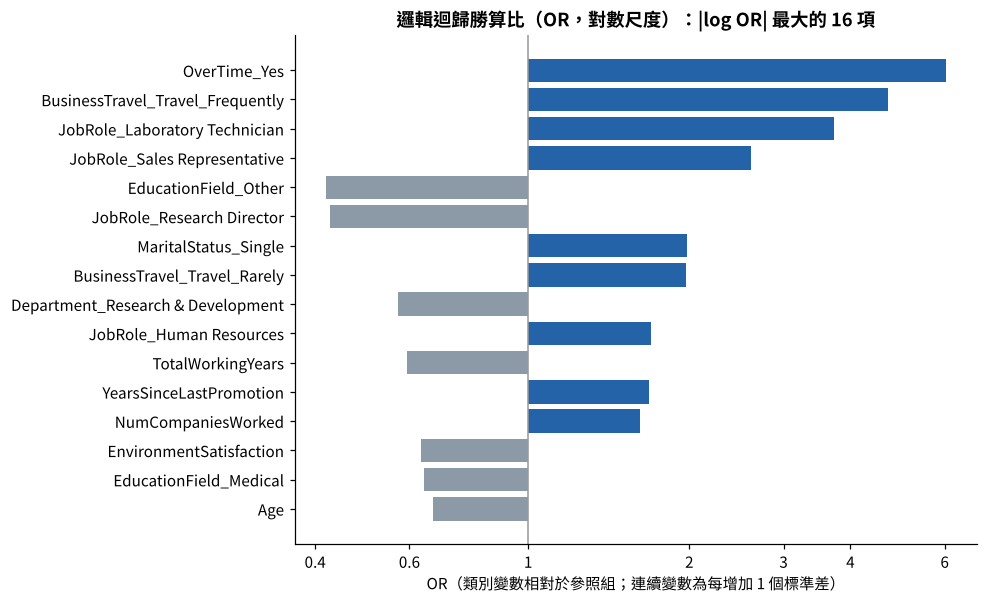

In [19]:
clf = best.named_steps["clf"]
names = best.named_steps["pre"].get_feature_names_out()
coef = pd.DataFrame({"Feature": [n.split("__", 1)[1] for n in names], "Coef": clf.coef_[0]})
coef["OddsRatio"] = np.exp(coef.Coef)
coef["Direction"] = np.where(coef.Coef > 0, "提高離職", "降低離職")
top = coef.reindex(coef.Coef.abs().sort_values(ascending=False).index).head(16).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.Feature, top.OddsRatio - 1, left=1, color=[C_LEFT if c > 0 else C_STAY for c in top.Coef])
ax.axvline(1, c="#999", lw=1); ax.set_xscale("log")
ax.set_xticks([0.4, 0.6, 1, 2, 3, 4, 6], ["0.4", "0.6", "1", "2", "3", "4", "6"]); ax.minorticks_off()
ax.set_title("邏輯迴歸勝算比（OR，對數尺度）：|log OR| 最大的 16 項")
ax.set_xlabel("OR（類別變數相對於參照組；連續變數為每增加 1 個標準差）")
savefig("09_odds_ratios")

In [20]:
pi = permutation_importance(best, X_te, y_te, scoring="average_precision", n_repeats=30, random_state=SEED)
imp = pd.DataFrame({"Feature": X_te.columns, "Importance": pi.importances_mean, "Std": pi.importances_std}).sort_values("Importance", ascending=False)
imp.head(12).round(4)

,Feature,Importance,Std
6,OverTime,0.239,0.030
15,JobSatisfaction,0.077,0.021
18,NumCompaniesWorked,0.063,0.018
28,YearsSinceLastPromotion,0.051,0.024
23,TotalWorkingYears,0.045,0.022
11,EnvironmentSatisfaction,0.042,0.026
13,JobInvolvement,0.037,0.017
9,DistanceFromHome,0.026,0.019
1,Department,0.024,0.024
0,BusinessTravel,0.022,0.015


**解讀**

勝算比（OR）定義為 exp(β)，表示在其他共變數維持不變的條件下，該變數變動一個單位時離職勝算（odds）的倍數變化；OR > 1 表示與較高的離職勝算相關，OR < 1 表示與較低的離職勝算相關（Hosmer et al., 2013）。類別變數以參照組比較（加班：無加班；出差：不出差；職位：Healthcare Representative；婚姻：離婚）；連續變數已標準化，OR 對應增加一個標準差。

- **加班**的條件關聯最強：在控制其他共變數後，有加班者的離職勝算約為無加班者的 6.0 倍（OR = 6.03）；排列重要性亦居首，且明顯高於其他變數。
- 其次為**經常出差**（相對於不出差，OR = 4.71）、**Laboratory Technician**（相對於 Healthcare Representative，OR = 3.72）、**Sales Representative**（OR = 2.61）與**單身**（相對於離婚，OR = 1.98）。
- **環境滿意度**（OR = 0.63）、**工作滿意度**（0.66）、**與現任主管共事年數**（0.68）、**工作投入度**（0.70）、**股票選擇權等級**（0.74）、**總工作年資**（0.59）每增加一個標準差，離職勝算均下降。
- **過去任職公司數**（OR = 1.62）與**距上次升遷年數**（OR = 1.68）在單變數檢定中未達顯著，但在控制年齡與年資後呈正向關聯，顯示其效果可能受資歷變數遮蔽（suppression）。
- 年資類變數之間存在高度共線性（例如 YearsAtCompany 的係數方向與單變數分析相反），其個別係數不宜單獨詮釋。
- EducationField_Other 與 Research Director 的係數絕對值雖大，但樣本數少，估計不穩定。

**方法說明**：模型採 L2 正則化，係數會向 0 收縮，因此此處的 OR 偏保守，且未報告信賴區間；所有 OR 皆為條件關聯，不應解讀為因果效果。

## 5. 風險分群與商業試算

### 5.1 每位員工的風險分數
用 5 折交叉驗證的**樣本外預測**給全部 1,470 人打分。

In [21]:
final = grid.best_estimator_
df["RiskScore"] = cross_val_predict(final, X, y, cv=cv, method="predict_proba")[:, 1]
print(f"全體樣本外 ROC-AUC {roc_auc_score(y, df.RiskScore):.3f}｜PR-AUC {average_precision_score(y, df.RiskScore):.3f}")

TIERS = [0, .15, .35, 1.01]
TIER_LABELS = ["低風險", "中風險", "高風險"]
df["RiskTier"] = pd.cut(df.RiskScore, TIERS, labels=TIER_LABELS, right=False).astype(str)
tier = rate_table("RiskTier"); tier["RiskTier"] = pd.Categorical(tier.RiskTier, TIER_LABELS, ordered=True)
tier = tier.sort_values("RiskTier")
tier["占全體"] = tier.Employees / n
tier["占離職者"] = tier.Leavers / left
tier

全體樣本外 ROC-AUC 0.830｜PR-AUC 0.620


,RiskTier,Employees,Leavers,AttritionRate,CI_low,CI_high,Lift,占全體,占離職者
1,低風險,984,61,0.062,0.049,0.079,0.385,0.669,0.257
0,中風險,252,40,0.159,0.119,0.209,0.985,0.171,0.169
2,高風險,234,136,0.581,0.517,0.643,3.605,0.159,0.574


**分群門檻**：低於 15%（約等於全公司離職率）為低風險；35% 以上為高風險（約全公司平均的 2 倍以上）。
門檻是管理決策，不是統計結果，可以依 HR 能處理的名單大小調整。

In [22]:
cur = df[df.AttritionFlag == 0]
prof = cur.groupby("RiskTier").agg(人數=("RiskScore", "size"), 平均風險=("RiskScore", "mean"),
                                   加班比例=("OverTime", lambda s: (s == "Yes").mean()),
                                   職級1比例=("JobLevel", lambda s: (s == 1).mean()),
                                   單身比例=("MaritalStatus", lambda s: (s == "Single").mean()),
                                   平均年資=("YearsAtCompany", "mean"), 月薪中位數=("MonthlyIncome", "median"),
                                   無股票比例=("StockOptionLevel", lambda s: (s == 0).mean())).reindex(TIER_LABELS)
print("在職員工的風險分群輪廓")
prof

在職員工的風險分群輪廓


,人數,平均風險,加班比例,職級1比例,單身比例,平均年資,月薪中位數,無股票比例
RiskTier,,,,,,,,
低風險,923,0.045,0.160,0.271,0.238,7.896,"5,561.000",0.342
中風險,212,0.229,0.396,0.481,0.363,6.094,"4,213.500",0.472
高風險,98,0.486,0.582,0.490,0.541,5.163,"4,091.000",0.622


### 5.2 離職成本（情境假設）
替補成本的估計差異很大：Gallup 估計替補一名員工的成本約為年薪的 0.5–2 倍（McFeely & Wigert, 2019）；
彙整 30 份個案研究的結果則顯示，除高階主管與醫師外，中位數約為年薪的 21%（Boushey & Glynn, 2012）。
本分析以 **50%** 為基準情境（即前者的下限），並列出 21% 與 100% 的敏感度分析，金額只用來比較相對大小。
資料沒有標示幣別，以下金額只當作相對單位。

- 已發生的離職成本 = Σ（離職者年薪 × 50%）
- 在職員工的**預期**離職成本 = Σ（風險分數 × 年薪 × 50%）

In [23]:
REPLACEMENT_RATE = 0.5
df["AnnualIncome"] = df.MonthlyIncome * 12
df["ReplacementCost"] = df.AnnualIncome * REPLACEMENT_RATE
df["ExpectedCost"] = np.where(df.AttritionFlag == 0, df.RiskScore * df.ReplacementCost, np.nan)

realized = df.loc[df.AttritionFlag == 1, "ReplacementCost"].sum()
cur = df[df.AttritionFlag == 0]
exp_cost = cur.groupby("RiskTier").agg(人數=("ExpectedCost", "size"), 預期離職人數=("RiskScore", "sum"),
                                      預期成本=("ExpectedCost", "sum")).reindex(TIER_LABELS)
exp_cost["成本占比"] = exp_cost.預期成本 / exp_cost.預期成本.sum()
print(f"已發生離職成本：{realized:,.0f}｜在職員工預期成本：{cur.ExpectedCost.sum():,.0f}")
sens = pd.DataFrame({f"{r:.0%}": {"已發生離職成本": realized / REPLACEMENT_RATE * r,
                                  "在職員工預期成本": cur.ExpectedCost.sum() / REPLACEMENT_RATE * r}
                     for r in [0.21, 0.5, 1.0]})
print("替補成本率敏感度分析："); display(sens.round(0))
exp_cost

已發生離職成本：6,807,246｜在職員工預期成本：4,416,435
替補成本率敏感度分析：


,21%,50%,100%
已發生離職成本,"2,859,043.000","6,807,246.000","13,614,492.000"
在職員工預期成本,"1,854,903.000","4,416,435.000","8,832,870.000"


,人數,預期離職人數,預期成本,成本占比
RiskTier,,,,
低風險,923,41.520,"1,561,110.495",0.353
中風險,212,48.447,"1,473,975.894",0.334
高風險,98,47.645,"1,381,348.658",0.313


**觀察**：高風險在職員工只有 98 人（約占在職 8%），預期成本卻占約三成；平均每人的預期成本約是低風險者的 8 倍。
低風險族群人數多，總額也不小，但無法用個別關懷處理，適合靠制度面（加班、薪資帶）改善。

### 5.3 情境：減少加班
把在職且有加班的員工逐一改成「無加班」、其他條件不變，用模型重新估計機率，得到「如果這個人不加班」的風險。
**這是模型估計，不是因果效果**：加班可能也反映了職位或專案壓力，真實效果通常比模型估計小。
Tableau 會用這個欄位做「加班改善比例」的參數試算。

In [24]:
final_full = grid.best_estimator_.fit(X, y)  # 用全部資料訓練的模型做情境比較
base_p = final_full.predict_proba(X)[:, 1]
X_cf = X.copy(); X_cf["OverTime"] = "No"
cf_p = final_full.predict_proba(X_cf)[:, 1]
df["RiskScore_Full"] = base_p
df["RiskScore_NoOT"] = cf_p          # 若不加班的風險（未加班者兩者相同）
df["RiskReduction_NoOT"] = base_p - cf_p

ot_cur = df[(df.AttritionFlag == 0) & (df.OverTime == "Yes")]
rows = []
for share in [0.25, 0.5, 1.0]:
    d_leavers = share * ot_cur.RiskReduction_NoOT.sum()
    d_cost = share * (ot_cur.RiskReduction_NoOT * ot_cur.ReplacementCost).sum()
    rows.append({"加班改善比例": f"{share:.0%}", "減少的預期離職人數": d_leavers, "減少的預期成本": d_cost})
print(f"在職且有加班：{len(ot_cur)} 人，平均風險 {ot_cur.RiskScore_Full.mean():.1%} → 不加班 {ot_cur.RiskScore_NoOT.mean():.1%}")
pd.DataFrame(rows)

在職且有加班：289 人，平均風險 18.8% → 不加班 4.2%


,加班改善比例,減少的預期離職人數,減少的預期成本
0,25%,10.547,"372,684.579"
1,50%,21.095,"745,369.158"
2,100%,42.190,"1,490,738.317"


## 6. 匯出 Tableau 資料表

In [25]:
emp_cols = ["EmployeeNumber", "Attrition", "AttritionFlag", "Age", "AgeGroup", "Gender_Label", "MaritalStatus_Label",
            "Department_Label", "JobRole", "JobLevel", "Education_Label", "EducationField", "OverTime_Label",
            "BusinessTravel_Label", "DistanceFromHome", "DistanceBand", "MonthlyIncome", "IncomeBand", "PercentSalaryHike",
            "StockOptionLevel_Label", "YearsAtCompany", "TenureBand", "YearsInCurrentRole", "YearsSinceLastPromotion",
            "PromotionGapBand", "YearsWithCurrManager", "TotalWorkingYears", "NumCompaniesWorked", "TrainingTimesLastYear",
            "PerformanceRating_Label", "EnvironmentSatisfaction", "JobSatisfaction", "RelationshipSatisfaction",
            "JobInvolvement", "WorkLifeBalance", "RiskScore", "RiskTier", "RiskScore_Full", "RiskScore_NoOT",
            "RiskReduction_NoOT", "AnnualIncome", "ReplacementCost", "ExpectedCost"]
emp = df[emp_cols].rename(columns=lambda c: c.replace("_Label", ""))
emp["Status"] = np.where(emp.AttritionFlag == 1, "離職", "在職")
emp["SurveyAvg"] = df[list(SURVEY)].mean(axis=1)
for c in ["AgeGroup", "TenureBand", "IncomeBand"]:   # Tableau 排序用
    emp[f"{c}Order"] = emp[c].map({v: i for i, v in enumerate(ORDER[c])})
emp.to_csv(OUT_TAB / "hr_employees.csv", index=False, encoding="utf-8-sig")

survey = (df[[ID, "Attrition"] + list(SURVEY)].melt(id_vars=[ID, "Attrition"], var_name="SurveyItem", value_name="Score")
          .assign(SurveyItem_ZH=lambda d: d.SurveyItem.map(SURVEY)))
survey["Status"] = np.where(survey.Attrition == "Yes", "離職", "在職")
survey["AttritionFlag"] = (survey.Attrition == "Yes").astype(int)
survey.to_csv(OUT_TAB / "hr_survey_long.csv", index=False, encoding="utf-8-sig")

FEATS = {"Department_Label": "部門", "JobRole": "職位", "JobLevel": "職級", "AgeGroup": "年齡層", "MaritalStatus_Label": "婚姻",
         "Gender_Label": "性別", "OverTime_Label": "加班", "BusinessTravel_Label": "出差", "DistanceBand": "通勤距離",
         "StockOptionLevel_Label": "股票選擇權", "IncomeBand": "月薪級距", "TenureBand": "年資", "PromotionGapBand": "距上次升遷",
         "Education_Label": "學歷", "WorkLifeBalance_Label": "工作與生活平衡", "JobInvolvement_Label": "工作投入度",
         "EnvironmentSatisfaction_Label": "環境滿意度", "JobSatisfaction_Label": "工作滿意度"}
drivers = pd.concat([rate_table(c).rename(columns={c: "Group"}).assign(Feature=v, SortOrder=lambda d: range(len(d)))
                     for c, v in FEATS.items()])
drivers["Group"] = drivers.Group.astype(str)
drivers[["Feature", "Group", "SortOrder", "Employees", "Leavers", "AttritionRate", "CI_low", "CI_high", "Lift"]] \
    .to_csv(OUT_TAB / "hr_drivers.csv", index=False, encoding="utf-8-sig")

coef.sort_values("Coef").to_csv(OUT_TAB / "hr_model_odds_ratios.csv", index=False, encoding="utf-8-sig")
gains_all = gains(y, df.RiskScore.values, pcts=np.arange(.05, 1.01, .05))
gains_all.to_csv(OUT_TAB / "hr_model_gains.csv", index=False, encoding="utf-8-sig")
pd.Series({**test_metrics, "C": grid.best_params_["clf__C"], "替補成本率": REPLACEMENT_RATE,
           "高風險門檻": TIERS[2], "中風險門檻": TIERS[1]}).rename("Value").to_csv(OUT_TAB / "hr_model_summary.csv", index_label="Metric", encoding="utf-8-sig")
for f in sorted(OUT_TAB.glob("*.csv")):
    print(f"{f.name:28s} {len(pd.read_csv(f)):>6,} 列")

hr_drivers.csv                   75 列
hr_employees.csv              1,470 列
hr_model_gains.csv               20 列
hr_model_odds_ratios.csv         44 列
hr_model_summary.csv              8 列
hr_survey_long.csv            7,350 列


## 7. 結論與建議

| 發現 | 證據 | 建議行動 |
|---|---|---|
| 加班是最強、且可管理的風險因素 | 離職率 30.5% vs 10.4%；控制其他共變數後 OR = 6.03 | 監控部門加班時數，設定加班上限或輪替；加班者列入季度關懷 |
| 前兩年是流失高峰 | 年資 0–2 年約 29–36%，3 年起降到 10–15% | 強化到職 90 天計畫、導師制度，第 12 個月做留任面談 |
| 低職級、低薪族群集中 | 職級 1 為 26%；月薪 <2.5k 為 34% | 檢視職級 1 的薪資帶與晉升路徑 |
| 風險會疊加 | 加班 × 職級 1 為 53%，再加單身 68% | 用風險分數鎖定名單，而非全面撒錢 |
| 股票選擇權與滿意度有保護效果 | 無股票 24%；投入度、環境滿意度低分 25–34% | 把股票配發延伸到職級 1–2；問卷最低分自動觸發主管面談 |
| 模型可用於排序 | 測試集前 20% 名單涵蓋約 62% 離職者 | HR 每季依風險名單排定面談，追蹤實際離職率驗證效果 |

**限制**：虛構資料、單一時間點、無因果識別；成本為情境假設。若導入真實資料，應以時間切分驗證（用過去預測未來），並以 A/B 方式評估留任措施的實際效果。

## 參考文獻

Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate: A practical and powerful approach to multiple testing. *Journal of the Royal Statistical Society: Series B (Methodological), 57*(1), 289–300. https://doi.org/10.1111/j.2517-6161.1995.tb02031.x

Boushey, H., & Glynn, S. J. (2012). *There are significant business costs to replacing employees*. Center for American Progress. https://www.americanprogress.org/article/there-are-significant-business-costs-to-replacing-employees/

Cohen, J. (1988). *Statistical power analysis for the behavioral sciences* (2nd ed.). Lawrence Erlbaum Associates.

Cramér, H. (1946). *Mathematical methods of statistics*. Princeton University Press.

Hosmer, D. W., Lemeshow, S., & Sturdivant, R. X. (2013). *Applied logistic regression* (3rd ed.). Wiley. https://doi.org/10.1002/9781118548387

Kerby, D. S. (2014). The simple difference formula: An approach to teaching nonparametric correlation. *Comprehensive Psychology, 3*, 11.IT.3.1. https://doi.org/10.2466/11.IT.3.1

Mann, H. B., & Whitney, D. R. (1947). On a test of whether one of two random variables is stochastically larger than the other. *The Annals of Mathematical Statistics, 18*(1), 50–60. https://doi.org/10.1214/aoms/1177730491

McFeely, S., & Wigert, B. (2019, March 13). *This fixable problem costs U.S. businesses $1 trillion*. Gallup. https://www.gallup.com/workplace/247391/fixable-problem-costs-businesses-trillion.aspx

Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE, 10*(3), e0118432. https://doi.org/10.1371/journal.pone.0118432

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953